# Seq2Seq Recipe Generation: RNN + Attention

Extending the baseline with an attention mechanism over encoder hidden states.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Natural%20language%20processing%28NLP%29/recipe-generation-seq2seq/seq2seq_rnn_with_attention.ipynb)

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
import numpy as np
import random
import re
import unicodedata
from torch.utils.data import Dataset, DataLoader
import csv
from collections import Counter
import ast
import matplotlib.ticker as ticker
import time
import math
import matplotlib.pyplot as plt
import pandas as pd, ast, re
import nltk
from torch.nn.utils.rnn import pad_sequence


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [15]:
def parse_list_column(col):
    try:
        return ast.literal_eval(col) if isinstance(col, str) and col.startswith('[') else []
    except Exception:
        return []

def preprocess_ingredients(ings):
    tokens = []
    for ing in ings:
        tokens.extend(re.findall(r"\b\w+\b", ing.lower()))
    return tokens


def preprocess_recipe(recipe):
    sentences = []
    for step in recipe:
        sentences.extend([sent.strip().lower() for sent in re.split(r'[.!?]', step) if sent.strip()])
    return sentences

def build_vocab(sequences):
    counter = Counter(w for seq in sequences for w in seq)
    vocab = {'PAD': 0, 'SOS': 1, 'EOS': 2, 'UNK': 3}
    idx = 4
    for word, _ in counter.most_common():
        vocab[word] = idx
        idx += 1
    return vocab


def indexes_from_sentence(vocab, sentence):
    return [vocab['SOS']] + [vocab.get(word, vocab['UNK']) for word in sentence] + [vocab['EOS']]

def tensor_from_sentence(vocab, sentence, max_len=None):
    indexes = indexes_from_sentence(vocab, sentence)
    return torch.tensor(indexes, dtype=torch.long)

def tensors_from_pair(pair, ingredient_vocab, recipe_vocab):
    input_tensor = tensor_from_sentence(ingredient_vocab, pair[0])
    target_tensor = tensor_from_sentence(recipe_vocab, pair[1])
    return (input_tensor, target_tensor)

In [16]:
class RecipeDataset(Dataset):
    def __init__(self, pairs, ingredient_vocab, recipe_vocab, max_len):
        self.pairs = pairs
        self.ingredient_vocab = ingredient_vocab
        self.recipe_vocab = recipe_vocab
        self.max_len = max_len
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        ing_tokens = self.pairs[idx][0]
        rec_tokens = self.pairs[idx][1]
        inp = tensor_from_sentence(self.ingredient_vocab, ing_tokens, self.max_len)
        out = tensor_from_sentence(self.recipe_vocab, rec_tokens, self.max_len)
        return inp, out

In [17]:
class AttnEncoderRNN1(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=2):
        super(AttnEncoderRNN1, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.embedding = nn.Embedding(input_size, hidden_size, padding_idx=0)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=num_layers, batch_first=True)

    def forward(self, input_seq):
        # input_seq: (batch_size, seq_len)
        embedded = self.embedding(input_seq)
        outputs, hidden = self.gru(embedded)
        return outputs, hidden

class AttnDecoderRNN1(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1, num_layers=2):
        super().__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.dropout_p = dropout_p
        self.num_layers = num_layers

        self.embedding = nn.Embedding(output_size, hidden_size, padding_idx=0)
        self.attn = nn.Linear(hidden_size * 2, hidden_size)
        self.attn_combine = nn.Linear(hidden_size * 2, hidden_size)
        self.dropout = nn.Dropout(self.dropout_p)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim=-1)

    def forward(self, input_step, hidden, encoder_outputs):

        embedded = self.embedding(input_step)
        embedded = self.dropout(embedded)

        hidden_last = hidden[-1].unsqueeze(1)

        attn_input = torch.cat((embedded, hidden_last), dim=2)
        encoder_outputs_reshaped = encoder_outputs.reshape(-1, self.hidden_size)
        attn_weights_input = self.attn(attn_input)

        attn_scores = torch.bmm(attn_weights_input, encoder_outputs.transpose(1, 2))
        attn_weights = F.softmax(attn_scores.squeeze(1), dim=1)

        attn_applied = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs)

        # Combine embedded input and attention output
        output = torch.cat((embedded, attn_applied), dim=2)
        output = self.attn_combine(output)
        output = F.relu(output)

        # Pass through GRU
        output, hidden = self.gru(output, hidden)

        # Final output layer
        output = self.out(output)
        output = self.softmax(output)

        return output, hidden, attn_weights

In [7]:
train_df = pd.read_csv("train.csv", nrows=90000)
train_df["Ingredients"] = train_df["Ingredients"].apply(ast.literal_eval)
train_df["Recipe"] = train_df["Recipe"].apply(ast.literal_eval)
# Apply preprocessing
train_df["ingredient_tokens"] = train_df["Ingredients"].apply(preprocess_ingredients)
train_df["recipe_tokens"] = train_df["Recipe"].apply(preprocess_recipe)

# Combine into (input, target) pairs
train_pairs = list(zip(train_df["ingredient_tokens"], train_df["recipe_tokens"]))
ingredient_vocab = build_vocab(train_df["ingredient_tokens"].tolist())
recipe_vocab = build_vocab(train_df["recipe_tokens"].tolist())


# Load and preprocess test.csv
test_df = pd.read_csv("test.csv")
test_df["Ingredients"] = test_df["Ingredients"].apply(ast.literal_eval)
test_df["Recipe"] = test_df["Recipe"].apply(ast.literal_eval)
test_df["ingredient_tokens"] = test_df["Ingredients"].apply(preprocess_ingredients)
test_df["recipe_tokens"] = test_df["Recipe"].apply(preprocess_recipe)

# Create test pairs
test_pairs = list(zip(test_df["ingredient_tokens"], test_df["recipe_tokens"]))

# Convert to tensor pairs
test_tensor_pairs = [tensors_from_pair(pair, ingredient_vocab, recipe_vocab) for pair in test_pairs]


In [18]:
print("Ingredient vocab size:", len(ingredient_vocab))
print("Recipe vocab size:", len(recipe_vocab))



Ingredient vocab size: 7252
Recipe vocab size: 346283


In [19]:
def collate_fn(batch):
    inputs, targets = zip(*batch)
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=0)
    return inputs_padded, targets_padded

max_len = 50
train_dataset = RecipeDataset(train_pairs, ingredient_vocab, recipe_vocab, max_len=max_len)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=collate_fn)


In [20]:
def train_batch(inputs, targets, encoder, decoder, enc_opt, dec_opt, criterion, teacher_forcing_ratio=0.1):
    inputs, targets = inputs.to(device), targets.to(device)
    batch_size, seq_len = targets.size()
    enc_opt.zero_grad()
    dec_opt.zero_grad()

    encoder_outputs, encoder_hidden = encoder(inputs)  # encoder_outputs: (B, L, H)
    decoder_input = torch.full((batch_size, 1), recipe_vocab['SOS'], dtype=torch.long, device=device)
    decoder_hidden = encoder_hidden

    loss = 0

    for t in range(seq_len):
        decoder_output, decoder_hidden, _ = decoder(decoder_input, decoder_hidden, encoder_outputs)

        if torch.any(targets[:, t] >= decoder_output.size(-1)):
            print("Target index out of bounds at timestep", t)
            print("Max target:", targets[:, t].max().item())
            print("Decoder output size:", decoder_output.size())
            raise ValueError("Target token exceeds decoder vocabulary size.")

        loss += criterion(decoder_output.squeeze(1), targets[:, t])
        use_teacher_forcing = random.random() < teacher_forcing_ratio
        top1 = decoder_output.argmax(-1)
        decoder_input = targets[:, t].unsqueeze(1) if use_teacher_forcing else top1

    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), max_norm=5)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), max_norm=5)
    enc_opt.step()
    dec_opt.step()

    return loss.item() / seq_len


In [21]:
def get_teacher_forcing_ratio(step):
    return 0.1

In [22]:
def showPlot(points):
    plt.figure(figsize=(8, 5))
    plt.plot(points)
    plt.title("Training Loss")
    plt.xlabel("Iterations (per plot_every)")
    plt.ylabel("Loss")
    plt.grid(True)
    ax = plt.gca()
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.show()


In [23]:
def train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=5):
    encoder.train()
    decoder.train()
    all_losses = []
    enc_opt = torch.optim.Adam(encoder.parameters(), lr=0.001)
    dec_opt = torch.optim.Adam(decoder.parameters(), lr=0.001)
    criterion = nn.NLLLoss(ignore_index=0)

    step = 0
    for epoch in range(1, n_epochs + 1):
        epoch_loss = 0
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            step += 1
            tf_ratio = get_teacher_forcing_ratio(step)
            loss = train_batch(inputs, targets, encoder, decoder, enc_opt, dec_opt, criterion, tf_ratio)
            epoch_loss += loss

        avg_epoch_loss = epoch_loss / len(train_loader)
        all_losses.append(avg_epoch_loss)
        print(f"Epoch {epoch} | TF ratio: {tf_ratio:.2f} | Loss: {avg_epoch_loss:.4f}")
    showPlot(all_losses)
    return all_losses


Epoch 1 | TF ratio: 0.10 | Loss: 9.5959
Epoch 2 | TF ratio: 0.10 | Loss: 8.7398
Epoch 3 | TF ratio: 0.10 | Loss: 8.4897
Epoch 4 | TF ratio: 0.10 | Loss: 8.3147
Epoch 5 | TF ratio: 0.10 | Loss: 8.0925


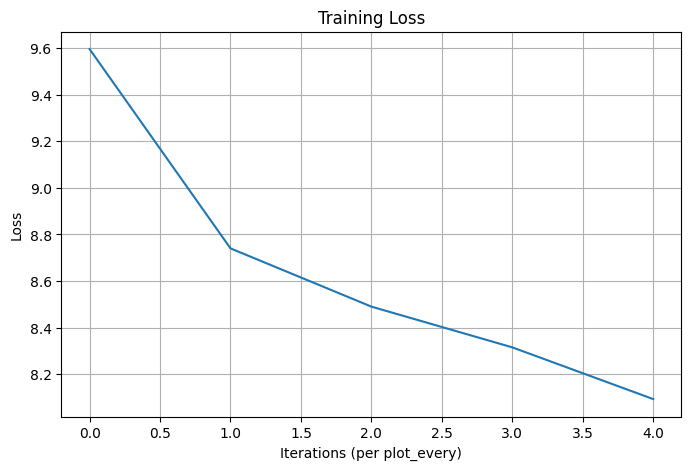

[9.595860001744228,
 8.739829815609395,
 8.48966220195675,
 8.314678450459908,
 8.092546924855128]

In [24]:
encoder = AttnEncoderRNN1(len(ingredient_vocab), hidden_size=256).to(device)
decoder = AttnDecoderRNN1(hidden_size=256, output_size=len(recipe_vocab)).to(device)

train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=5)


In [25]:
def evaluate_model_loss(encoder, decoder, tensor_pairs, criterion, max_length=50):
    total_loss = 0
    with torch.no_grad():
        for input_tensor, target_tensor in tensor_pairs:
            input_tensor = input_tensor.unsqueeze(0).to(device)
            target_tensor = target_tensor.to(device)

            encoder_outputs, encoder_hidden = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden

            loss = 0
            for di in range(target_tensor.size(0)):
                decoder_output, decoder_hidden, _ = decoder(decoder_input, decoder_hidden, encoder_outputs)
                loss += criterion(decoder_output.squeeze(1), target_tensor[di].unsqueeze(0))
                topv, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach().unsqueeze(1)

                if topi.item() == recipe_vocab['EOS']:
                    break

            total_loss += loss.item() / target_tensor.size(0)

    return total_loss / len(tensor_pairs)


In [26]:
def generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=50):
    input_tensor = input_tensor.unsqueeze(0).to(device)
    encoder_outputs, encoder_hidden = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
    decoder_hidden = encoder_hidden
    output_tokens = []

    for _ in range(max_length):
        decoder_output, decoder_hidden, _ = decoder(decoder_input, decoder_hidden, encoder_outputs)
        topv, topi = decoder_output.topk(1, dim=-1)
        token_id = topi.squeeze().item()

        if token_id == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
        output_tokens.append(word)
        decoder_input = torch.tensor([[token_id]], device=device)

    return output_tokens


In [27]:
# Reverse vocab
recipe_vocab_inv = {v: k for k, v in recipe_vocab.items()}

# Print 5 sample outputs
random_indices = random.sample(range(len(test_pairs)), 5)
for i, idx in enumerate(random_indices):
    ingredients_tokens, ground_truth_tokens = test_pairs[idx]
    input_tensor = tensor_from_sentence(ingredient_vocab, ingredients_tokens, max_len)
    generated_tokens = generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=max_len)

    print(f"--- Example {i+1} (Test Index: {idx}) ---")
    print("Ingredients:", " ".join(ingredients_tokens))
    print("Ground Truth Recipe:", " ".join(ground_truth_tokens))
    print("Generated Recipe:", " ".join(generated_tokens))
    print()


--- Example 1 (Test Index: 1054) ---
Ingredients: 1 c sugar 1 c water 2 tbsp red cinnamon drops 6 medium size firm tart apples whole cloves
Ground Truth Recipe: combine sugar, water and red cinnamon drops in 1 1/2-quart casserole cook about 3 minutes in radarange oven core and pare apples stick 3 or 4 cloves into each apple place apples in the red cinnamon syrup cook about 7 to 8 minutes or until apples are tender but firm turn apples every 2 1/2 minutes cool apples in syrup before serving
Generated Recipe: SOS wash scallops and drain

--- Example 2 (Test Index: 309) ---
Ingredients: 2 lb hamburger meat seasoned 1 can greenbeans 1 can whole corn mashed potatoes
Ground Truth Recipe: brown ground meat layer meat, greenbeans, corn, meat, greenbeans, corn until gone
Generated Recipe: SOS you will also need vegetable cooking spray set aside

--- Example 3 (Test Index: 587) ---
Ingredients: 5 lb potatoes 1 pt diced sweet pickle 2 ribs diced celery 1 diced onion 6 eggs boiled and diced 1 2 to

In [28]:
!pip install nltk bert-score --quiet
!pip install bert-score
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from bert_score import score
import torch
import pandas as pd
import ast, re
from tqdm import tqdm

nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 106.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 98.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 107.7 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [33]:

def evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device='cpu'):
    bleu_scores = []
    meteor_scores = []
    references = []
    candidates = []

    encoder.eval()
    decoder.eval()

    for input_tensor, target_tensor in test_tensor_pairs[:200]:
        input_tensor = input_tensor.unsqueeze(0).to(device)
        target_tensor = target_tensor.to(device)

        with torch.no_grad():
            encoder_outputs, encoder_hidden = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden
            generated_tokens = []

            for _ in range(max_len):
                decoder_output, decoder_hidden, _ = decoder(decoder_input, decoder_hidden, encoder_outputs)
                topi = decoder_output.argmax(-1)
                token_id = topi.squeeze().item()
                if token_id == recipe_vocab['EOS']:
                    break
                word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
                generated_tokens.append(word)
                decoder_input = topi

        reference = [next((k for k, v in recipe_vocab.items() if v == idx.item()), "<UNK>")
                     for idx in target_tensor[1:-1]]
        candidate = generated_tokens

        if reference and candidate:
            smoothie = SmoothingFunction().method4
            bleu = sentence_bleu([reference], candidate, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)
            meteor = meteor_score([reference], candidate)
            bleu_scores.append(bleu)
            meteor_scores.append(meteor)
            references.append(' '.join(reference))
            candidates.append(' '.join(candidate))

    if candidates and references:
        P, R, F1 = score(candidates, references, lang='en', verbose=False)
        bertscore_f1 = F1.mean().item()
    else:
        bertscore_f1 = 0.0

    print("\n=== Average Scores on Test Set ===")
    print(f"BLEU-4: {sum(bleu_scores)/len(bleu_scores):.4f}" if bleu_scores else "BLEU-4: No valid scores")
    print(f"METEOR: {sum(meteor_scores)/len(meteor_scores):.4f}" if meteor_scores else "METEOR: No valid scores")
    print(f"BERTScore (F1): {bertscore_f1:.4f}")

    encoder.train()
    decoder.train()


evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device=device)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Average Scores on Test Set ===
BLEU-4: 0.0011
METEOR: 0.0033
BERTScore (F1): 0.8004


In [35]:
import pandas as pd
import ast, re, torch
from tqdm import tqdm



def clean_and_tokenize_ingredients(ingredient_text):
    try:
        ingredients = ast.literal_eval(ingredient_text) if isinstance(ingredient_text, str) else []
    except:
        ingredients = []
    tokens = []
    for ing in ingredients:
        tokens.extend(re.findall(r'\b\w+\b', ing.lower()))
    return tokens

def generate_recipe(ingredient_tokens, encoder, decoder, ingredient_vocab, recipe_vocab, max_len=100):
    input_indexes = [ingredient_vocab.get(w, ingredient_vocab['UNK']) for w in ingredient_tokens]
    input_tensor = torch.tensor([ingredient_vocab['SOS']] + input_indexes + [ingredient_vocab['EOS']],
                                dtype=torch.long).unsqueeze(0).to(device)

    # Attention encoder returns outputs and hidden
    encoder_outputs, encoder_hidden = encoder(input_tensor)
    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=input_tensor.device)
    decoder_hidden = encoder_hidden
    output_words = []

    for _ in range(max_len):
        decoder_output, decoder_hidden, _ = decoder(decoder_input, decoder_hidden, encoder_outputs)
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == next_token), "<UNK>")
        output_words.append(word)
        decoder_input = topi.detach()
    return ' '.join(output_words)


# Load CSV
df = pd.read_csv("generated_filled.csv")

# Example: fill "Recipe - Baseline 1" column
baseline1_outputs = []
for ing_text in tqdm(df["Ingredients"], desc="Generating Baseline 2"):
    tokens = clean_and_tokenize_ingredients(ing_text)
    gen1 = generate_recipe(tokens, encoder, decoder, ingredient_vocab, recipe_vocab)
    baseline1_outputs.append(gen1)

df["Recipe - Baseline 2"] = baseline1_outputs

# Save updated file as CSV
df.to_csv("generated_filled2.csv", index=False, encoding='utf-8-sig')
print("Updated predictions written to: generated_filled2.csv")


Generating Baseline 2: 100%|██████████| 1081/1081 [00:10<00:00, 99.07it/s] 

Updated predictions written to: generated_filled2.csv


In [36]:
df = pd.read_csv("generated_filled.csv")
print(df[["Ingredients", "Recipe - Baseline 2"]].head(10))


                                         Ingredients  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...   
2  ["1 large box lemon jello", "1 large can crush...   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...   
5  ["1 c. white sugar", "1 pkg. chopped sugared d...   
6  ["1 (10 oz.) bag chopped broccoli", "4 chicken...   
7  ["1 bunch broccoli, chopped", "1 medium purple...   
8  ["1/2 c. each dried pinto beans, pink beans an...   
9  ["2 c. sugar", "1/2 tsp. salt", "1 c. hot wate...   

                     Recipe - Baseline 2  
0            SOS combine all ingredients  
1  SOS combine all ingredients set aside  
2       SOS mix all ingredients together  
3  SOS cut chicken into bite-size pieces  
4  SOS wash scallops and drain set aside  
5            SOS combine all ingredients  
6                  SOS brown meat; drain  
7            SOS combine all ingredient